Họ tên: Phan Công Trí - MSSV: 6451071080
Kích thước bộ dữ liệu FNA Breast Cancer: (569, 31)
Phân bố nhãn thực tế (0 = Malignant - Ác tính, 1 = Benign - Lành tính):
Diagnosis
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Silhouette Coefficient (k=2) : 0.3434
Độ chính xác phân cụm (Accuracy so với chẩn đoán thực tế): 0.9051 (90.51%)

Classification Report (K-Means Clustering vs Chẩn đoán thực tế):

                     precision    recall  f1-score   support

Malignant (Ác tính)     0.9072    0.8302    0.8670       212
 Benign (Lành tính)     0.9040    0.9496    0.9262       357

           accuracy                         0.9051       569
          macro avg     0.9056    0.8899    0.8966       569
       weighted avg     0.9052    0.9051    0.9042       569



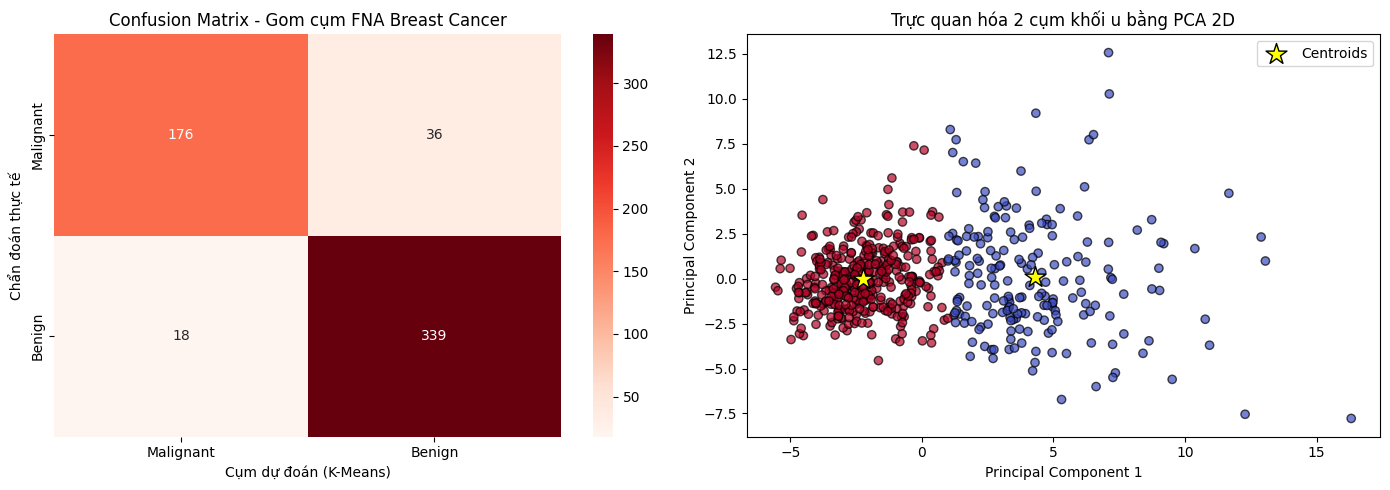

In [ ]:
# ==================== BÀI 5 (TRANG 29) ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score
from scipy.stats import mode

# 1. Tải bộ dữ liệu Breast Cancer Wisconsin (Diagnostic) - FNA
cancer = load_breast_cancer()
df_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df_cancer['Diagnosis'] = cancer.target # 0: Malignant (Ác tính), 1: Benign (Lành tính)

print("Kích thước bộ dữ liệu FNA Breast Cancer:", df_cancer.shape)
print("Phân bố nhãn thực tế (0 = Malignant - Ác tính, 1 = Benign - Lành tính):")
print(df_cancer['Diagnosis'].value_counts())
display(df_cancer.head())

# 2. Tiền xử lý & Chuẩn hóa dữ liệu (StandardScaler giúp K-Means không bị lệch bởi các thuộc tính có đơn vị lớn)
X_fna = cancer.data
y_true = cancer.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_fna)

# 3. Áp dụng thuật toán K-Means với k = 2 (Gom thành 2 nhóm: Lành tính và Ác tính)
kmeans_fna = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters_fna = kmeans_fna.fit_predict(X_scaled)

# Ánh xạ nhãn cụm của K-Means sang nhãn thực tế (0 và 1) để đánh giá độ chính xác
y_pred_mapped = np.zeros_like(clusters_fna)
for i in range(2):
    mask = (clusters_fna == i)
    y_pred_mapped[mask] = mode(y_true[mask], keepdims=True)[0]

# 4. Đánh giá hiệu quả gom cụm
acc_fna = accuracy_score(y_true, y_pred_mapped)
sil_fna = silhouette_score(X_scaled, clusters_fna)

print(f"\nSilhouette Coefficient (k=2) : {sil_fna:.4f}")
print(f"Độ chính xác phân cụm (Accuracy so với chẩn đoán thực tế): {acc_fna:.4f} ({acc_fna*100:.2f}%)")

print("\nClassification Report (K-Means Clustering vs Chẩn đoán thực tế):\n")
print(classification_report(y_true, y_pred_mapped, target_names=['Malignant (Ác tính)', 'Benign (Lành tính)'], digits=4))

# 5. Vẽ Confusion Matrix và Biểu đồ phân cụm 2D (dùng PCA giảm chiều dữ liệu xuống 2D để trực quan hóa)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm_fna = confusion_matrix(y_true, y_pred_mapped)
sns.heatmap(cm_fna, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Malignant', 'Benign'],
            yticklabels=['Malignant', 'Benign'], ax=ax[0])
ax[0].set_title('Confusion Matrix - Gom cụm FNA Breast Cancer')
ax[0].set_xlabel('Cụm dự đoán (K-Means)')
ax[0].set_ylabel('Chẩn đoán thực tế')

# Biểu đồ Scatter sau khi giảm chiều bằng PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
scatter = ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_pred_mapped, cmap='coolwarm', alpha=0.7, edgecolors='k')
centers_pca = pca.transform(kmeans_fna.cluster_centers_)
ax[1].scatter(centers_pca[:, 0], centers_pca[:, 1], c='yellow', s=250, marker='*', edgecolors='black', label='Centroids')
ax[1].set_title('Trực quan hóa 2 cụm khối u bằng PCA 2D')
ax[1].set_xlabel('Principal Component 1')
ax[1].set_ylabel('Principal Component 2')
ax[1].legend()

plt.tight_layout()
plt.show()